## Importing Libraries

In [1]:
import os
import numpy as np
import librosa
import pandas as pd

## Extracting Audio Features

In [3]:
DATASET_PATH=r"C:\Users\Rakshit\Downloads\Data\genres_original"
features=[]
labels=[]
for genre in os.listdir(DATASET_PATH):  #looping through genre folders
    genre_path=os.path.join(DATASET_PATH,genre)
    if not os.path.isdir(genre_path):
        continue
    print(f"Processing:{genre}")
    for file in os.listdir(genre_path):  #looping through each audio file in a genre folder
        file_path=os.path.join(genre_path,file)
        try:
            audio,sr=librosa.load(file_path,duration=30,sr=22050)   #loading the audio file
            
            
            mfcc=librosa.feature.mfcc(y=audio,sr=sr,n_mfcc=20)       #extracting 20 mfcc features with their mean and standard deviation
            mfcc_mean=np.mean(mfcc,axis=1)
            mfcc_std=np.std(mfcc,axis=1)

           
            chroma=librosa.feature.chroma_stft(y=audio,sr=sr)         #etracting chroma with 12 components
            chroma_mean=np.mean(chroma,axis=1)
            chroma_std=np.std(chroma,axis=1)

           
            centroid = librosa.feature.spectral_centroid(y=audio,sr=sr)     #extracting spectral centroid
            centroid_mean= np.mean(centroid)
            centroid_std=np.std(centroid)

           
            bandwidth=librosa.feature.spectral_bandwidth(y=audio,sr=sr)      #extracting bandwidth
            bandwidth_mean=np.mean(bandwidth)
            bandwidth_std=np.std(bandwidth)

            
            rolloff=librosa.feature.spectral_rolloff(y=audio,sr=sr)        #extracting rolloff
            rolloff_mean=np.mean(rolloff)
            rolloff_std=np.std(rolloff)

            
            rms=librosa.feature.rms(y=audio)                 #extracting root mean squared energy
            rms_mean=np.mean(rms)
            rms_std=np.std(rms)

            
            tempo,_=librosa.beat.beat_track(y=audio,sr=sr)        #extracting tempo

            #combining all the audio features
            feature_vector=np.hstack([mfcc_mean,mfcc_std,chroma_mean,chroma_std,centroid_mean,centroid_std,bandwidth_mean,bandwidth_std,rolloff_mean,rolloff_std,rms_mean,rms_std,tempo])
            
            features.append(feature_vector)
            labels.append(genre)

        except Exception as e:
            print(f"Skipping file: {file_path} due to some error!!!")   #exception handling in case of some error
            continue


Processing:blues
Processing:classical
Processing:country
Processing:disco
Processing:hiphop
Processing:jazz


C:\Users\Rakshit\AppData\Local\Temp\ipykernel_19432\1041367257.py:12: UserWarning: PySoundFile failed. Trying audioread instead.
  audio,sr=librosa.load(file_path,duration=30,sr=22050)   #loading the audio file
C:\Users\Rakshit\anaconda3\Lib\site-packages\librosa\core\audio.py:184: FutureWarning: librosa.core.audio.__audioread_load
	Deprecated as of librosa version 0.10.0.
	It will be removed in librosa version 1.0.
  y, sr_native = __audioread_load(path, offset, duration, dtype)


Skipping file: C:\Users\Rakshit\Downloads\Data\genres_original\jazz\jazz.00054.wav due to some error!!!
Processing:metal
Processing:pop
Processing:reggae
Processing:rock


## Creating Dataset

In [6]:
columns=[]  #creating column names
for i in range(1,21):
    columns.append(f"mfcc{i}_mean")
for i in range(1,21):
    columns.append(f"mfcc{i}_std")
for i in range(1,13):
    columns.append(f"chroma{i}_mean")
for i in range(1,13):
    columns.append(f"chroma{i}_std")
columns=columns+["centroid_mean","centroid_std","bandwidth_mean","bandwidth_std","rolloff_mean","rolloff_std","rms_mean","rms_std","tempo"]
df=pd.DataFrame(features,columns=columns)            #creating dataframe
df["label"]=labels
print(df.shape)
df.to_csv("music_features.csv",index=False)          #creating CSV file
df

(999, 74)


,mfcc1_mean,mfcc2_mean,mfcc3_mean,mfcc4_mean,mfcc5_mean,mfcc6_mean,mfcc7_mean,mfcc8_mean,mfcc9_mean,mfcc10_mean,...,centroid_mean,centroid_std,bandwidth_mean,bandwidth_std,rolloff_mean,rolloff_std,rms_mean,rms_std,tempo,label
0,-113.619385,121.553017,-19.151056,42.345768,-6.371168,18.613033,-13.692060,15.339378,-12.283618,10.973775,...,1784.416546,360.194166,2002.657106,292.966459,3806.418650,949.383832,0.130192,0.053201,123.046875,blues
1,-207.581512,123.997147,8.939115,35.870758,2.919971,21.518787,-8.555368,23.355938,-10.101037,11.906444,...,1529.871314,613.197888,2038.612143,462.482296,3548.986873,1725.338349,0.095892,0.048724,67.999589,blues
2,-90.776344,140.448608,-29.100559,31.687340,-13.975973,25.741682,-13.644712,11.623112,-11.775921,9.700466,...,1552.637786,395.649207,1747.382028,275.954142,3041.089944,884.842654,0.175494,0.052465,161.499023,blues
3,-199.462006,150.094742,5.649167,26.870144,1.755441,14.236880,-4.828873,9.297849,-0.753142,8.147393,...,1070.110059,429.542379,1596.244204,408.212651,2185.061787,1222.372310,0.141139,0.079623,63.024009,blues
4,-160.291855,126.195763,-35.602501,22.151169,-32.487640,10.862023,-23.357162,0.500523,-11.804770,1.203878,...,1835.507008,585.947299,1748.367477,297.422362,3581.003346,1253.847208,0.091540,0.048011,135.999178,blues
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
994,-153.616486,109.894516,-23.106590,59.007462,-7.527995,19.730127,-16.486076,18.083521,-22.215626,15.403847,...,2008.537046,531.172751,2106.349206,297.689203,4254.124276,1105.817773,0.079441,0.018599,103.359375,rock
995,-142.442062,116.238441,-32.190319,49.114609,-8.395415,22.872288,-18.311134,20.106487,-22.106911,10.796755,...,2006.009248,425.954224,2068.224879,286.218381,4147.166589,1020.737891,0.076425,0.024282,117.453835,rock
996,-125.065109,115.203308,-48.004681,52.843109,-13.491938,21.765408,-12.428562,20.139965,-18.370886,10.119690,...,2077.166788,481.365929,1926.895810,273.268373,4030.750627,896.860464,0.081583,0.017962,129.199219,rock
997,-224.994049,123.669685,-9.775933,56.605724,10.427107,20.634146,-10.257257,15.573306,-8.251973,12.805178,...,1398.581574,490.501770,1817.813570,330.271788,3014.673437,1154.501536,0.083834,0.034733,73.828125,rock


In [46]:
import pandas as pd
df=pd.read_csv("music_features.csv")
df

,mfcc1_mean,mfcc2_mean,mfcc3_mean,mfcc4_mean,mfcc5_mean,mfcc6_mean,mfcc7_mean,mfcc8_mean,mfcc9_mean,mfcc10_mean,...,centroid_mean,centroid_std,bandwidth_mean,bandwidth_std,rolloff_mean,rolloff_std,rms_mean,rms_std,tempo,label
0,-113.619385,121.553017,-19.151056,42.345768,-6.371168,18.613033,-13.692060,15.339378,-12.283618,10.973775,...,1784.416546,360.194166,2002.657106,292.966459,3806.418650,949.383832,0.130192,0.053201,123.046875,blues
1,-207.581512,123.997147,8.939115,35.870758,2.919971,21.518787,-8.555368,23.355938,-10.101037,11.906444,...,1529.871314,613.197888,2038.612143,462.482296,3548.986873,1725.338349,0.095892,0.048724,67.999589,blues
2,-90.776344,140.448608,-29.100559,31.687340,-13.975973,25.741682,-13.644712,11.623112,-11.775921,9.700466,...,1552.637786,395.649207,1747.382028,275.954142,3041.089944,884.842654,0.175494,0.052465,161.499023,blues
3,-199.462006,150.094742,5.649167,26.870144,1.755441,14.236880,-4.828873,9.297849,-0.753142,8.147393,...,1070.110059,429.542379,1596.244204,408.212651,2185.061787,1222.372310,0.141139,0.079623,63.024009,blues
4,-160.291855,126.195763,-35.602501,22.151169,-32.487640,10.862023,-23.357162,0.500523,-11.804770,1.203878,...,1835.507008,585.947299,1748.367477,297.422362,3581.003346,1253.847208,0.091540,0.048011,135.999178,blues
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
994,-153.616486,109.894516,-23.106590,59.007462,-7.527995,19.730127,-16.486076,18.083521,-22.215626,15.403847,...,2008.537046,531.172751,2106.349206,297.689203,4254.124276,1105.817773,0.079441,0.018599,103.359375,rock
995,-142.442062,116.238441,-32.190319,49.114609,-8.395415,22.872288,-18.311134,20.106487,-22.106911,10.796755,...,2006.009248,425.954224,2068.224879,286.218381,4147.166589,1020.737891,0.076425,0.024282,117.453835,rock
996,-125.065109,115.203308,-48.004681,52.843109,-13.491938,21.765408,-12.428562,20.139965,-18.370886,10.119690,...,2077.166788,481.365929,1926.895810,273.268373,4030.750627,896.860464,0.081583,0.017962,129.199219,rock
997,-224.994049,123.669685,-9.775933,56.605724,10.427107,20.634146,-10.257257,15.573306,-8.251973,12.805178,...,1398.581574,490.501770,1817.813570,330.271788,3014.673437,1154.501536,0.083834,0.034733,73.828125,rock


## Data Analysis

In [47]:
print(df.shape)
print(df.info())
print(df.isnull().sum())

(999, 74)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 999 entries, 0 to 998
Data columns (total 74 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   mfcc1_mean      999 non-null    float64
 1   mfcc2_mean      999 non-null    float64
 2   mfcc3_mean      999 non-null    float64
 3   mfcc4_mean      999 non-null    float64
 4   mfcc5_mean      999 non-null    float64
 5   mfcc6_mean      999 non-null    float64
 6   mfcc7_mean      999 non-null    float64
 7   mfcc8_mean      999 non-null    float64
 8   mfcc9_mean      999 non-null    float64
 9   mfcc10_mean     999 non-null    float64
 10  mfcc11_mean     999 non-null    float64
 11  mfcc12_mean     999 non-null    float64
 12  mfcc13_mean     999 non-null    float64
 13  mfcc14_mean     999 non-null    float64
 14  mfcc15_mean     999 non-null    float64
 15  mfcc16_mean     999 non-null    float64
 16  mfcc17_mean     999 non-null    float64
 17  mfcc18_mean     999 non-n

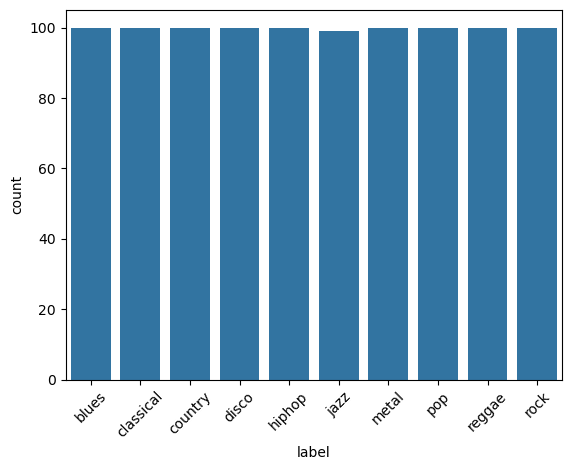

In [48]:
import seaborn as sns
import matplotlib.pyplot as plt

sns.countplot(x="label", data=df)
plt.xticks(rotation=45)
plt.show()

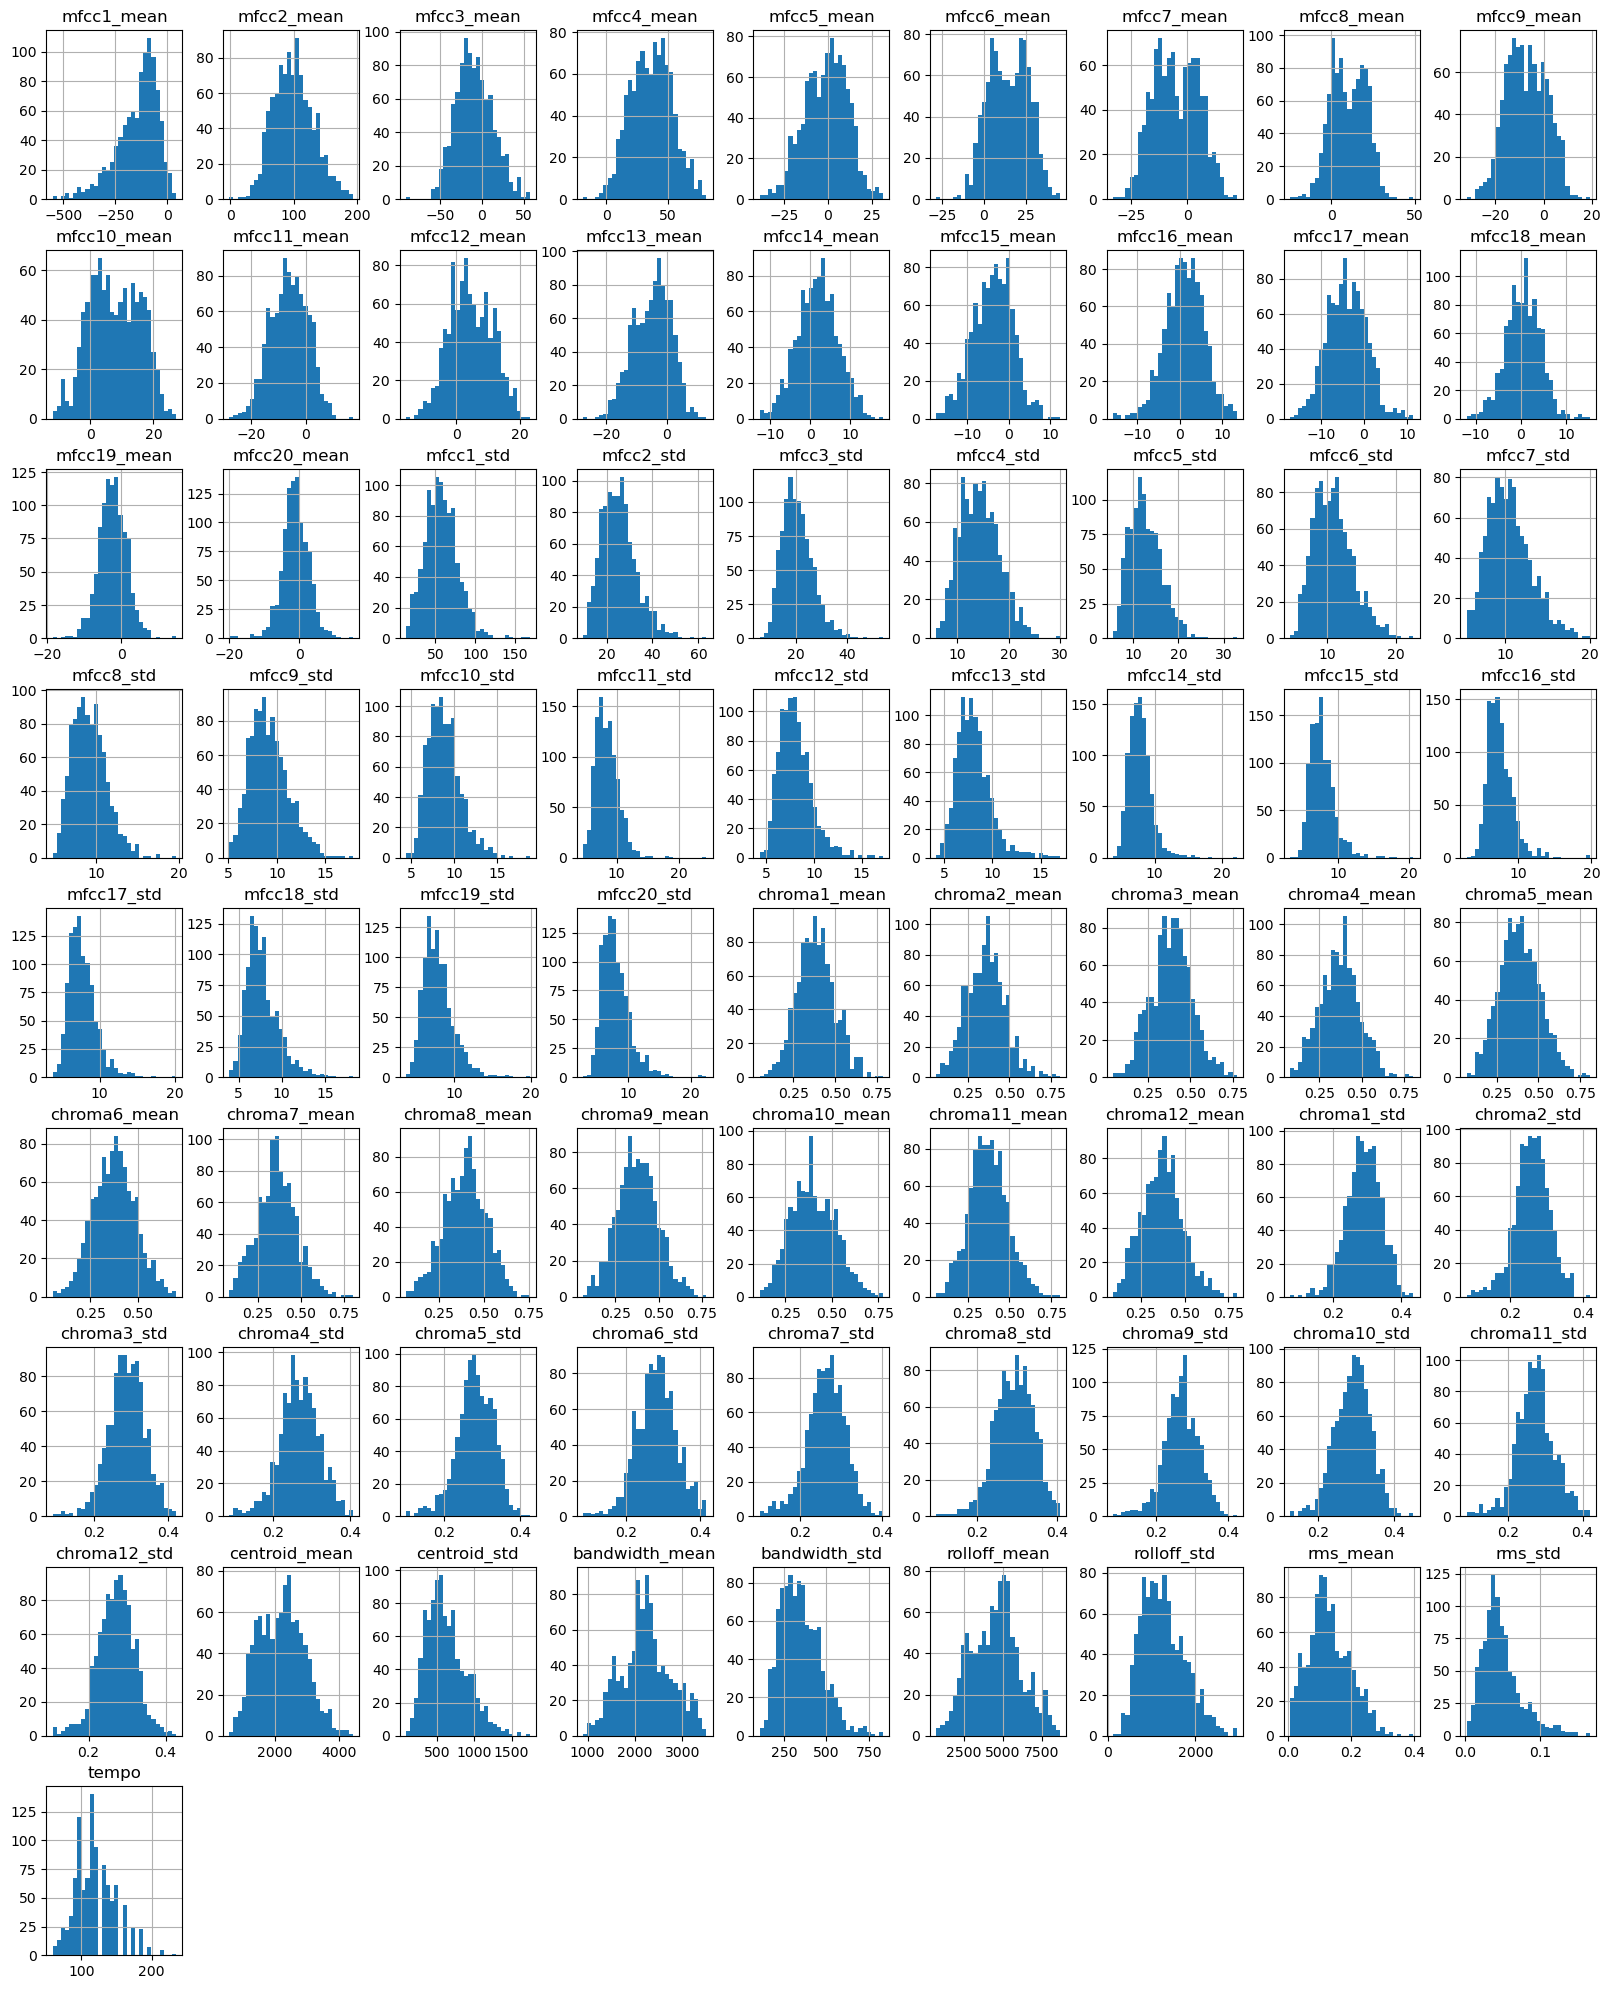

In [49]:
df.hist(figsize=(20,25), bins=30)
plt.show()

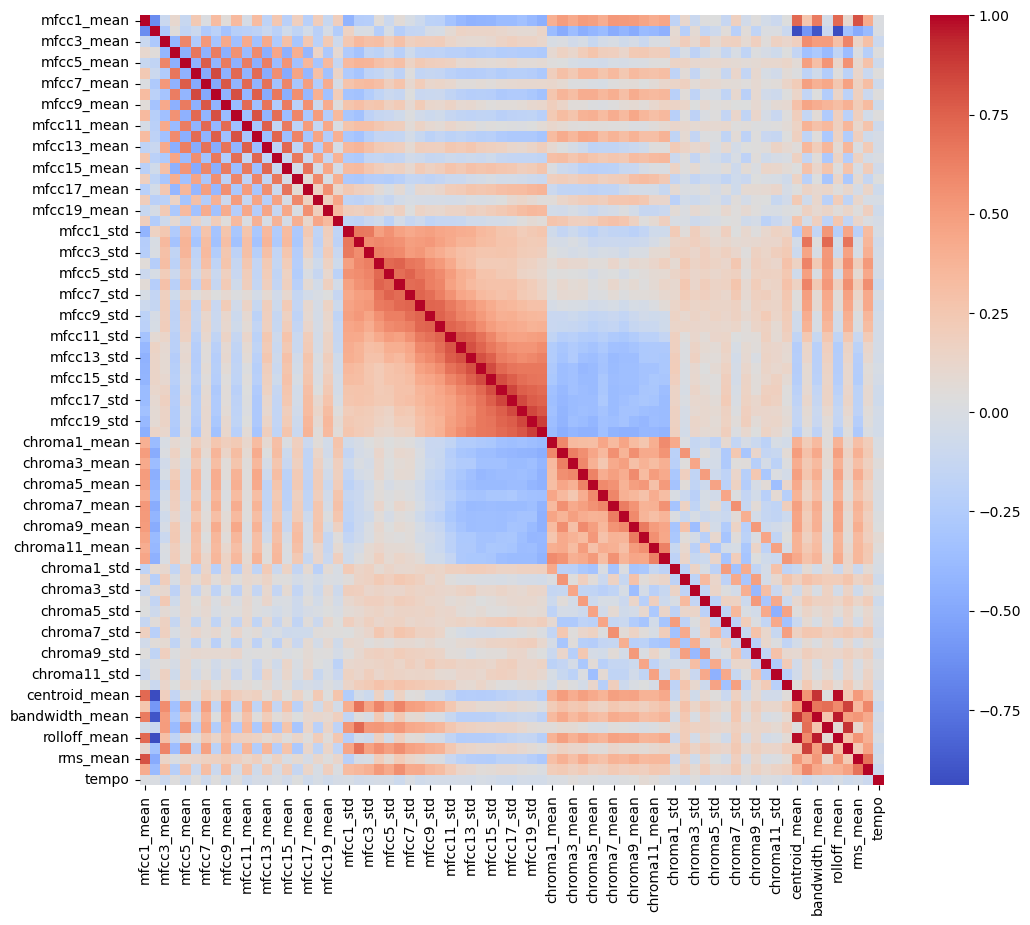

In [50]:
plt.figure(figsize=(12,10))
sns.heatmap(df.drop("label", axis=1).corr(), cmap="coolwarm")
plt.show()

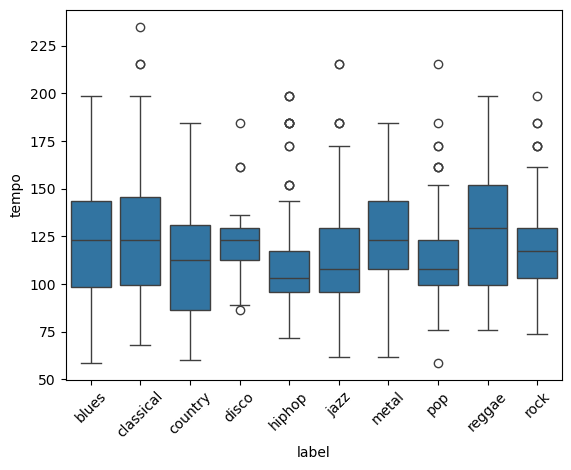

In [51]:
sns.boxplot(x="label", y="tempo", data=df)
plt.xticks(rotation=45)
plt.show()

## Spliiting the DataFrame

In [52]:
x=df.drop("label",axis=1)
y=df["label"]
x.shape
y.shape

(999,)

## Dividing into Training and Testing Data

In [53]:
from sklearn.model_selection import train_test_split
x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=0.2,random_state=42)

## Scaling the Data

In [54]:
from sklearn.preprocessing import StandardScaler
scaler=StandardScaler()
x_train=scaler.fit_transform(x_train)
x_test=scaler.transform(x_test)

## Training the Models

In [55]:
from sklearn.linear_model import LogisticRegression
lr=LogisticRegression(max_iter=1000)
lr.fit(x_train,y_train)

LogisticRegression(max_iter=1000)

In [56]:
from sklearn.neighbors import KNeighborsClassifier
knn=KNeighborsClassifier(n_neighbors=5)
knn.fit(x_train,y_train)

KNeighborsClassifier()

In [57]:
from sklearn.tree import DecisionTreeClassifier
dt= DecisionTreeClassifier()
dt.fit(x_train,y_train)

DecisionTreeClassifier()

In [58]:
from sklearn.svm import SVC
svm=SVC(C=10,gamma='scale',kernel='rbf',probability=True)
svm.fit(x_train,y_train)

SVC(C=10, probability=True)

In [59]:
from sklearn.ensemble import RandomForestClassifier
rf=RandomForestClassifier(n_estimators=400,max_depth=30,min_samples_split=5,random_state=42)
rf.fit(x_train,y_train)

RandomForestClassifier(max_depth=30, min_samples_split=5, n_estimators=400,
                       random_state=42)

In [60]:
from xgboost import XGBClassifier
from sklearn.preprocessing import LabelEncoder
le=LabelEncoder()
y_train_enc=le.fit_transform(y_train)
y_test_enc=le.transform(y_test)
xgb=XGBClassifier(n_estimators=250,max_depth=6,learning_rate=0.1)
xgb.fit(x_train,y_train_enc)

XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=None, device=None, early_stopping_rounds=None,
              enable_categorical=False, eval_metric=None, feature_types=None,
              feature_weights=None, gamma=None, grow_policy=None,
              importance_type=None, interaction_constraints=None,
              learning_rate=0.1, max_bin=None, max_cat_threshold=None,
              max_cat_to_onehot=None, max_delta_step=None, max_depth=6,
              max_leaves=None, min_child_weight=None, missing=nan,
              monotone_constraints=None, multi_strategy=None, n_estimators=250,
              n_jobs=None, num_parallel_tree=None, ...)

In [61]:
from sklearn.ensemble import VotingClassifier
voting_model= VotingClassifier(estimators=[('svm',svm),('rf',rf),('xgb',xgb)],voting='soft')
voting_model.fit(x_train,y_train)

VotingClassifier(estimators=[('svm', SVC(C=10, probability=True)),
                             ('rf',
                              RandomForestClassifier(max_depth=30,
                                                     min_samples_split=5,
                                                     n_estimators=400,
                                                     random_state=42)),
                             ('xgb',
                              XGBClassifier(base_score=None, booster=None,
                                            callbacks=None,
                                            colsample_bylevel=None,
                                            colsample_bynode=None,
                                            colsample_bytree=None, device=None,
                                            early_stopping_rounds=None,
                                            enable_categorical...
                                            feature_weights=None, gamma=None,
                                            grow_policy=None,
                                            importance_type=None,
                                            interaction_constraints=None,
                                            learning_rate=0.1, max_bin=None,
                                            max_cat_threshold=None,
                                            max_cat_to_onehot=None,
                                            max_delta_step=None, max_depth=6,
                                            max_leaves=None,
                                            min_child_weight=None, missing=nan,
                                            monotone_constraints=None,
                                            multi_strategy=None,
                                            n_estimators=250, n_jobs=None,
                                            num_parallel_tree=None, ...))],
                 voting='soft')

## Evaluating the Models

In [62]:
from sklearn.metrics import accuracy_score, classification_report

In [63]:
y_pred_lr=lr.predict(x_test)
print("Logistic Regression:\n", classification_report(y_test, y_pred_lr))

Logistic Regression:
               precision    recall  f1-score   support

       blues       0.61      0.67      0.64        21
   classical       0.86      1.00      0.92        12
     country       0.60      0.62      0.61        24
       disco       0.80      0.55      0.65        22
      hiphop       0.75      0.60      0.67        15
        jazz       0.85      0.85      0.85        27
       metal       0.79      0.83      0.81        18
         pop       0.71      0.79      0.75        19
      reggae       0.52      0.55      0.53        22
        rock       0.52      0.55      0.54        20

    accuracy                           0.69       200
   macro avg       0.70      0.70      0.70       200
weighted avg       0.70      0.69      0.69       200



In [65]:
y_pred_knn=knn.predict(x_test)
print("K Nearest Neighbor:\n", classification_report(y_test, y_pred_knn))

K Nearest Neighbor:
               precision    recall  f1-score   support

       blues       0.71      0.57      0.63        21
   classical       0.62      0.83      0.71        12
     country       0.71      0.71      0.71        24
       disco       0.52      0.50      0.51        22
      hiphop       0.44      0.73      0.55        15
        jazz       0.88      0.78      0.82        27
       metal       0.76      0.89      0.82        18
         pop       0.61      0.74      0.67        19
      reggae       0.73      0.36      0.48        22
        rock       0.39      0.35      0.37        20

    accuracy                           0.64       200
   macro avg       0.64      0.65      0.63       200
weighted avg       0.65      0.64      0.63       200



In [66]:
y_pred_dt=dt.predict(x_test)
print("Decision Tree:\n", classification_report(y_test, y_pred_dt))

Decision Tree:
               precision    recall  f1-score   support

       blues       0.46      0.29      0.35        21
   classical       0.65      0.92      0.76        12
     country       0.56      0.42      0.48        24
       disco       0.33      0.36      0.35        22
      hiphop       0.23      0.33      0.27        15
        jazz       0.68      0.63      0.65        27
       metal       0.68      0.72      0.70        18
         pop       0.56      0.74      0.64        19
      reggae       0.38      0.36      0.37        22
        rock       0.25      0.20      0.22        20

    accuracy                           0.48       200
   macro avg       0.48      0.50      0.48       200
weighted avg       0.48      0.48      0.47       200



In [67]:
y_pred_svm=svm.predict(x_test)
print("SVM:\n", classification_report(y_test, y_pred_svm))

SVM:
               precision    recall  f1-score   support

       blues       0.76      0.76      0.76        21
   classical       0.69      0.92      0.79        12
     country       0.68      0.79      0.73        24
       disco       0.79      0.68      0.73        22
      hiphop       0.71      0.67      0.69        15
        jazz       0.88      0.81      0.85        27
       metal       0.76      0.89      0.82        18
         pop       0.88      0.79      0.83        19
      reggae       0.74      0.64      0.68        22
        rock       0.50      0.50      0.50        20

    accuracy                           0.74       200
   macro avg       0.74      0.74      0.74       200
weighted avg       0.75      0.74      0.74       200



In [68]:
y_pred_rf=rf.predict(x_test)
print("Random Forest:\n", classification_report(y_test, y_pred_rf))

Random Forest:
               precision    recall  f1-score   support

       blues       0.87      0.62      0.72        21
   classical       0.71      1.00      0.83        12
     country       0.67      0.67      0.67        24
       disco       0.79      0.68      0.73        22
      hiphop       0.67      0.80      0.73        15
        jazz       0.96      0.89      0.92        27
       metal       0.69      1.00      0.82        18
         pop       0.80      0.84      0.82        19
      reggae       0.79      0.68      0.73        22
        rock       0.47      0.40      0.43        20

    accuracy                           0.74       200
   macro avg       0.74      0.76      0.74       200
weighted avg       0.75      0.74      0.74       200



In [70]:
y_pred_xgb=xgb.predict(x_test)
print("XG Boost:\n", classification_report(y_test_enc, y_pred_xgb))

XG Boost:
               precision    recall  f1-score   support

           0       0.75      0.57      0.65        21
           1       0.80      1.00      0.89        12
           2       0.75      0.75      0.75        24
           3       0.64      0.73      0.68        22
           4       0.73      0.73      0.73        15
           5       0.92      0.85      0.88        27
           6       0.78      1.00      0.88        18
           7       0.84      0.84      0.84        19
           8       0.70      0.64      0.67        22
           9       0.50      0.45      0.47        20

    accuracy                           0.74       200
   macro avg       0.74      0.76      0.74       200
weighted avg       0.74      0.74      0.74       200



In [71]:
y_pred_vote = voting_model.predict(x_test)
print("Voting Model:\n",classification_report(y_test, y_pred_vote))

Voting Model:
               precision    recall  f1-score   support

       blues       0.88      0.67      0.76        21
   classical       0.80      1.00      0.89        12
     country       0.73      0.67      0.70        24
       disco       0.73      0.73      0.73        22
      hiphop       0.79      0.73      0.76        15
        jazz       0.96      0.89      0.92        27
       metal       0.78      1.00      0.88        18
         pop       0.80      0.84      0.82        19
      reggae       0.71      0.68      0.70        22
        rock       0.50      0.55      0.52        20

    accuracy                           0.77       200
   macro avg       0.77      0.78      0.77       200
weighted avg       0.77      0.77      0.76       200



## Confusion Matrix for Best Fit Model(Voting Model)

In [72]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

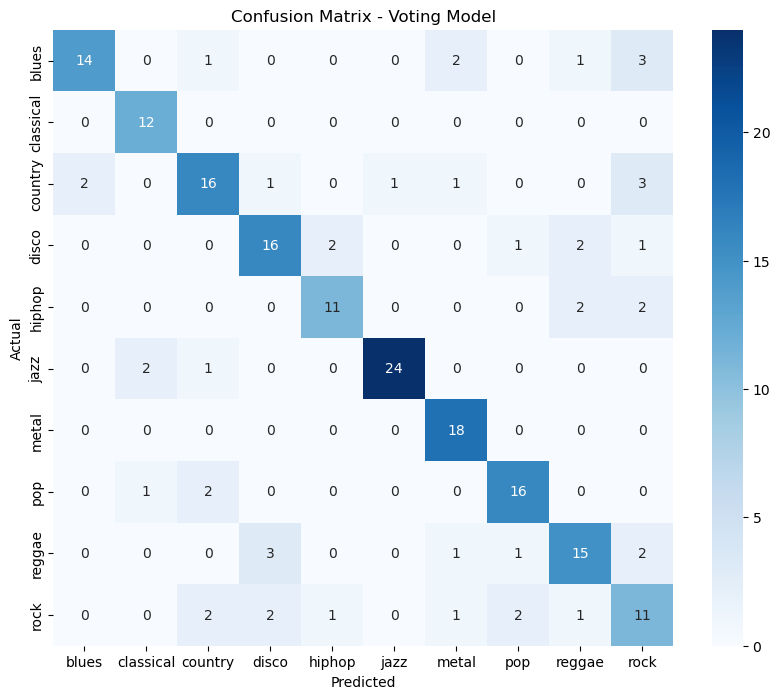

In [73]:
cm=confusion_matrix(y_test,y_pred_vote)
genres=sorted(y.unique())
plt.figure(figsize=(10,8))
sns.heatmap(cm,annot=True,fmt='d',cmap='Blues',xticklabels=genres,yticklabels=genres)
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix - Voting Model")
plt.show()

## Exporting Model

In [74]:
import joblib
joblib.dump(voting_model,"Music_Genre_Classifier.pkl")
joblib.dump(scaler,"scaler.pkl")

['scaler.pkl']